# 📈 Microsoft (MSFT) Stock Price Analysis & Forecasting 2021-2026
## 🚀 Advanced EDA with Animated Visualizations, Interactive Dashboard & Data Storytelling

---

### 📋 Project Objectives
- Comprehensive Animated EDA with Plotly + Seaborn
- Professional Interactive Dashboard
- Data Storytelling Narrative
- Statistical Analysis
- Problem Identification & Solution Mapping
- Actionable Use Cases & Conclusion

---

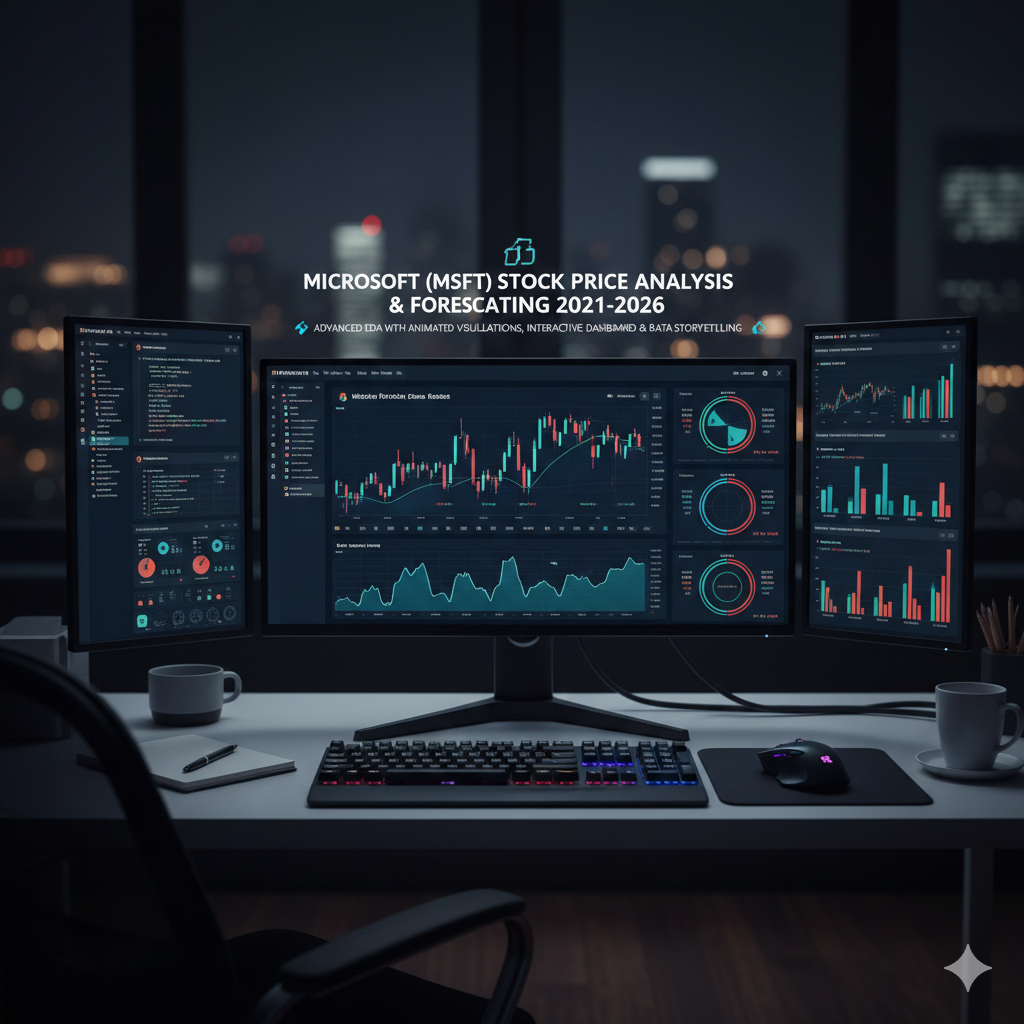

In [1]:
from IPython.display import Image
Image(filename = "/kaggle/input/microsoft/other/default/1/GoldPulse.png", width = 400, height = 400)

In [2]:
# 📚 Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


## 📥 1. Data Loading & Preparation

In [3]:
# Load Dataset
df = pd.read_csv('/kaggle/input/microsoft-stock-price-analysis-and-forecasting/MSFT_5years_cleaned.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Feature Engineering
df['year_month'] = df['date'].dt.to_period('M').astype(str)
df['daily_range'] = df['high'] - df['low']
df['daily_range_pct'] = (df['daily_range'] / df['open']) * 100
df['cumulative_return'] = (1 + df['price_change_pct']/100).cumprod() - 1

print(f'📊 Dataset Shape: {df.shape}')
print(f'📅 Date Range: {df["date"].min().date()} to {df["date"].max().date()}')
df.head()

📊 Dataset Shape: (1254, 16)
📅 Date Range: 2021-02-04 to 2026-02-02


,date,close,high,low,open,volume,price_change,price_change_pct,day_of_week,month,year,quarter,year_month,daily_range,daily_range_pct,cumulative_return
0,2021-02-04,232.22,233.40,230.64,232.84,25296100,NaN,NaN,3,2,2021,1,2021-02,2.75,1.18,NaN
1,2021-02-05,232.40,233.44,230.69,232.43,18054800,0.18,0.08,4,2,2021,1,2021-02,2.74,1.18,0.00
2,2021-02-08,232.66,233.82,231.07,233.31,22211900,0.26,0.11,0,2,2021,1,2021-02,2.75,1.18,0.00
3,2021-02-09,233.91,234.86,231.61,232.08,23565000,1.25,0.54,1,2,2021,1,2021-02,3.24,1.40,0.01
4,2021-02-10,233.00,235.97,231.14,235.09,22186700,-0.91,-0.39,2,2,2021,1,2021-02,4.83,2.05,0.00


## 📖 2. Data Storytelling Narrative

---

### 🎬 The Microsoft Stock Journey (2021-2026)

> *"From pandemic recovery to AI revolution - Microsoft's remarkable 5-year stock performance tells a story of innovation, resilience, and market leadership."*

**Chapter 1: The Starting Point (Feb 2021)**
Microsoft stock began our analysis period at ~$232, riding the wave of pandemic-driven digital transformation.

**Chapter 2: The Growth Era (2021-2022)**
Cloud computing (Azure) and enterprise software demand fueled consistent growth, pushing prices above $300.

**Chapter 3: The Tech Selloff (2022)**
Rising interest rates triggered a tech sector correction. MSFT showed resilience compared to peers.

**Chapter 4: The AI Revolution (2023-2024)**
OpenAI partnership and Copilot integration catalyzed unprecedented growth, breaking $400.

**Chapter 5: New Heights (2025-2026)**
AI-driven enterprise adoption pushed MSFT toward $480+, nearly doubling from 2021 levels.

---

## 📊 3. Animated Exploratory Data Analysis

In [4]:
# 🎬 ANIMATED: Stock Price Evolution Over Time
fig = px.line(df, x='date', y='close', 
              title='🎬 MSFT Stock Price Journey (2021-2026)',
              labels={'close': 'Closing Price ($)', 'date': 'Date'})

# Add animation frames
frames = []
for i in range(50, len(df), 25):
    frames.append(go.Frame(data=[go.Scatter(x=df['date'][:i], y=df['close'][:i], mode='lines', 
                                             line=dict(color='#2ecc71', width=2))]))

fig.update_layout(
    template='plotly_dark',
    updatemenus=[dict(type='buttons', showactive=False, y=1.15, x=0.5, xanchor='center',
                      buttons=[dict(label='▶ Play', method='animate', 
                                   args=[None, dict(frame=dict(duration=50), fromcurrent=True)])])],
    height=500
)
fig.frames = frames
fig.show()
fig.show(renderer='iframe')

In [5]:
# 🎬 ANIMATED: Yearly Price Distribution Animation
yearly_data = df.groupby('year')['close'].apply(list).reset_index()

fig = px.box(df, x='year', y='close', color='year',
             animation_frame='quarter',
             title='🎬 ANIMATED: Price Distribution by Year and Quarter',
             labels={'close': 'Closing Price ($)', 'year': 'Year'},
             color_discrete_sequence=px.colors.qualitative.Bold)
fig.update_layout(template='plotly_dark', height=500)
fig.show()
fig.show(renderer='iframe')

In [6]:
# 🎬 ANIMATED: Monthly Volume Evolution
monthly_vol = df.groupby('year_month').agg({'volume': 'sum', 'close': 'mean'}).reset_index()
monthly_vol['volume_M'] = monthly_vol['volume'] / 1e6

fig = px.bar(monthly_vol, x='year_month', y='volume_M',
             title='🎬 Monthly Trading Volume Evolution',
             labels={'volume_M': 'Volume (Millions)', 'year_month': 'Month'},
             color='volume_M', color_continuous_scale='Viridis')
fig.update_layout(template='plotly_dark', height=400, xaxis_tickangle=-45)
fig.show()
fig.show(renderer='iframe')

### 📈 Seaborn Statistical Visualizations

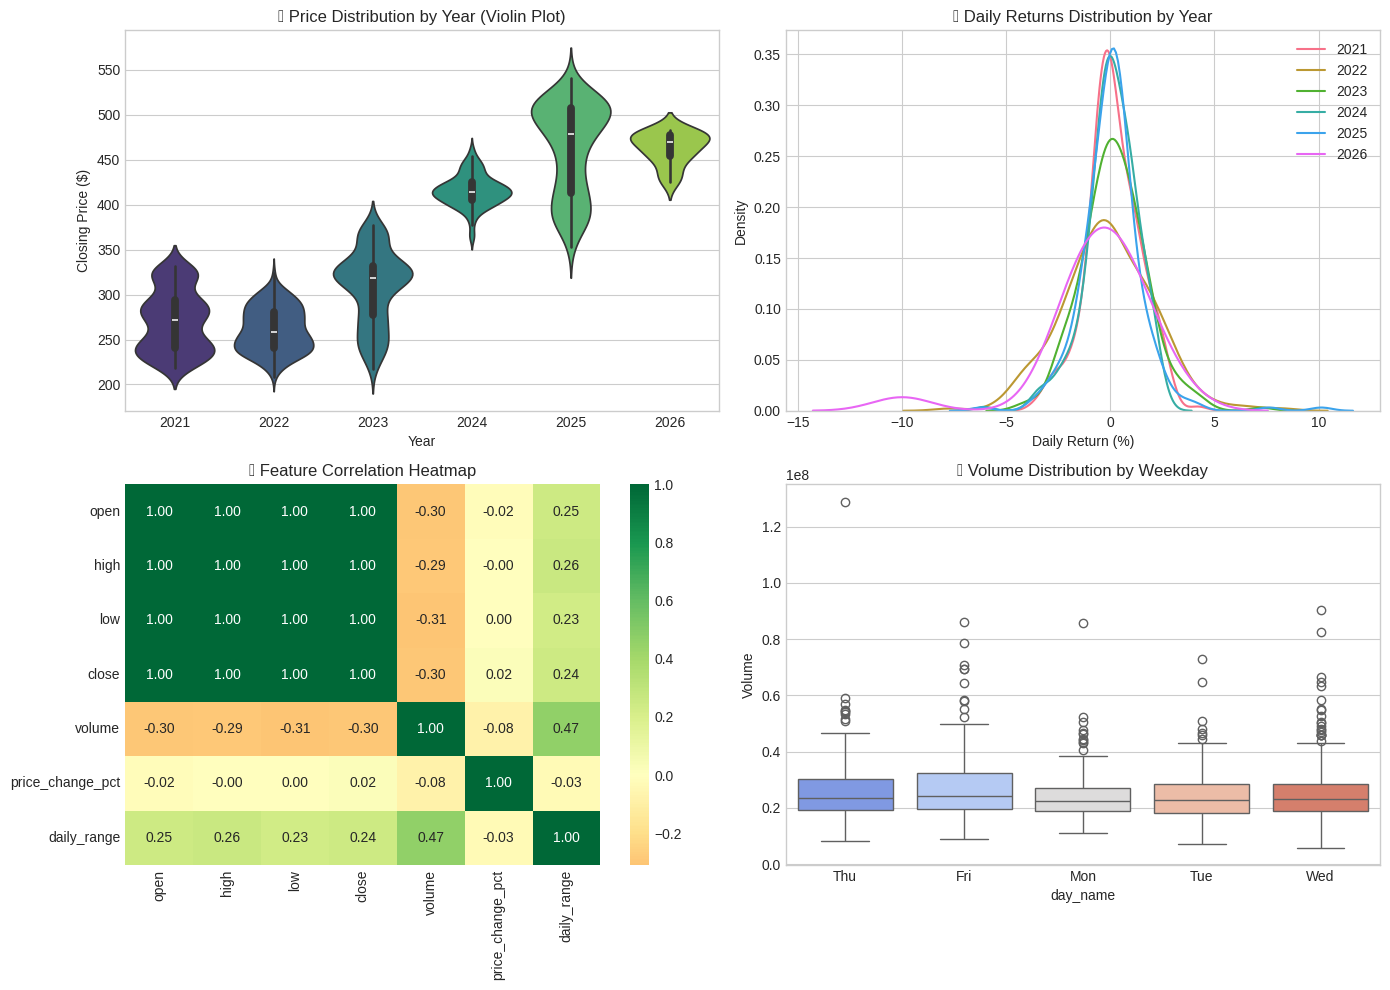

In [7]:
# Seaborn: Price Distribution by Year
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Violin Plot - Price by Year
sns.violinplot(data=df, x='year', y='close', palette='viridis', ax=axes[0,0])
axes[0,0].set_title('📊 Price Distribution by Year (Violin Plot)', fontsize=12)
axes[0,0].set_xlabel('Year')
axes[0,0].set_ylabel('Closing Price ($)')

# 2. KDE Plot - Daily Returns
for year in df['year'].unique():
    subset = df[df['year'] == year]['price_change_pct'].dropna()
    sns.kdeplot(subset, label=str(year), ax=axes[0,1])
axes[0,1].set_title('📊 Daily Returns Distribution by Year', fontsize=12)
axes[0,1].legend()
axes[0,1].set_xlabel('Daily Return (%)')

# 3. Heatmap - Correlation
corr_cols = ['open', 'high', 'low', 'close', 'volume', 'price_change_pct', 'daily_range']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='RdYlGn', center=0, ax=axes[1,0], fmt='.2f')
axes[1,0].set_title('📊 Feature Correlation Heatmap', fontsize=12)

# 4. Box Plot - Volume by Day of Week
day_names = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri'}
df['day_name'] = df['day_of_week'].map(day_names)
sns.boxplot(data=df, x='day_name', y='volume', palette='coolwarm', ax=axes[1,1])
axes[1,1].set_title('📊 Volume Distribution by Weekday', fontsize=12)
axes[1,1].set_ylabel('Volume')

plt.tight_layout()
plt.show()


## 🎛️ 4. Professional Interactive Dashboard

In [8]:
# 📊 PROFESSIONAL INTERACTIVE DASHBOARD
fig = make_subplots(
    rows=3, cols=2,
    subplot_titles=('📈 Stock Price Trend', '📊 Volume Analysis',
                    '📉 Daily Returns', '🎯 Moving Averages',
                    '📊 Quarterly Performance', '🔥 Volatility Heatmap'),
    specs=[[{"type": "scatter"}, {"type": "bar"}],
           [{"type": "histogram"}, {"type": "scatter"}],
           [{"type": "bar"}, {"type": "heatmap"}]],
    vertical_spacing=0.12, horizontal_spacing=0.08
)

# Calculate MAs
df['MA20'] = df['close'].rolling(20).mean()
df['MA50'] = df['close'].rolling(50).mean()

# 1. Stock Price
fig.add_trace(go.Scatter(x=df['date'], y=df['close'], name='Close', line=dict(color='#2ecc71')), row=1, col=1)

# 2. Volume
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in df['price_change'].fillna(0)]
fig.add_trace(go.Bar(x=df['date'], y=df['volume']/1e6, name='Volume', marker_color=colors), row=1, col=2)

# 3. Returns Distribution
fig.add_trace(go.Histogram(x=df['price_change_pct'].dropna(), nbinsx=50, name='Returns', marker_color='#3498db'), row=2, col=1)

# 4. Moving Averages
fig.add_trace(go.Scatter(x=df['date'], y=df['close'], name='Price', line=dict(color='#2ecc71', width=1)), row=2, col=2)
fig.add_trace(go.Scatter(x=df['date'], y=df['MA20'], name='MA20', line=dict(color='#e74c3c', width=2)), row=2, col=2)
fig.add_trace(go.Scatter(x=df['date'], y=df['MA50'], name='MA50', line=dict(color='#3498db', width=2)), row=2, col=2)

# 5. Quarterly Performance
qtr_perf = df.groupby(['year', 'quarter']).apply(lambda x: ((x['close'].iloc[-1] - x['close'].iloc[0]) / x['close'].iloc[0]) * 100).reset_index(name='return')
qtr_perf['label'] = qtr_perf['year'].astype(str) + '-Q' + qtr_perf['quarter'].astype(str)
fig.add_trace(go.Bar(x=qtr_perf['label'], y=qtr_perf['return'], name='Qtr Return', 
                     marker_color=['#2ecc71' if x > 0 else '#e74c3c' for x in qtr_perf['return']]), row=3, col=1)

# 6. Monthly Volatility Heatmap
monthly_vol = df.groupby(['year', 'month'])['price_change_pct'].std().reset_index()
pivot = monthly_vol.pivot(index='year', columns='month', values='price_change_pct')
fig.add_trace(go.Heatmap(z=pivot.values, x=pivot.columns, y=pivot.index, colorscale='RdYlGn_r', name='Volatility'), row=3, col=2)

fig.update_layout(height=900, title_text='🎛️ MSFT Stock Analysis - Interactive Dashboard',
                  template='plotly_dark', showlegend=False)
fig.show()
fig.show(renderer='iframe')

## 📊 5. Statistical Analysis

In [9]:
# 📊 COMPREHENSIVE STATISTICAL ANALYSIS
print('='*70)
print('📊 STATISTICAL ANALYSIS - MSFT STOCK (2021-2026)')
print('='*70)

returns = df['price_change_pct'].dropna()

# Basic Statistics
print('\n📈 DESCRIPTIVE STATISTICS')
print(f"{'Metric':<30} {'Value':>15}")
print('-'*45)
print(f"{'Mean Daily Return':<30} {returns.mean():>14.4f}%")
print(f"{'Median Daily Return':<30} {returns.median():>14.4f}%")
print(f"{'Std Deviation (Volatility)':<30} {returns.std():>14.4f}%")
print(f"{'Annualized Return':<30} {returns.mean() * 252:>14.2f}%")
print(f"{'Annualized Volatility':<30} {returns.std() * np.sqrt(252):>14.2f}%")
print(f"{'Sharpe Ratio':<30} {(returns.mean() * 252) / (returns.std() * np.sqrt(252)):>14.2f}")

# Distribution Tests
print('\n📊 DISTRIBUTION ANALYSIS')
skewness = returns.skew()
kurtosis = returns.kurtosis()
print(f"{'Skewness':<30} {skewness:>14.4f}")
print(f"{'Kurtosis':<30} {kurtosis:>14.4f}")

# Normality Test
stat, p_value = stats.shapiro(returns.sample(min(5000, len(returns)), random_state=42))
print(f"\n{'Shapiro-Wilk Test p-value':<30} {p_value:>14.6f}")
print(f"{'Distribution':<30} {'Non-Normal' if p_value < 0.05 else 'Normal':>15}")

# Value at Risk
var_95 = np.percentile(returns, 5)
var_99 = np.percentile(returns, 1)
print(f"\n{'VaR (95%)':<30} {var_95:>14.2f}%")
print(f"{'VaR (99%)':<30} {var_99:>14.2f}%")

📊 STATISTICAL ANALYSIS - MSFT STOCK (2021-2026)

📈 DESCRIPTIVE STATISTICS
Metric                                   Value
---------------------------------------------
Mean Daily Return                      0.0617%
Median Daily Return                    0.0679%
Std Deviation (Volatility)             1.6397%
Annualized Return                       15.54%
Annualized Volatility                   26.03%
Sharpe Ratio                             0.60

📊 DISTRIBUTION ANALYSIS
Skewness                               0.0322
Kurtosis                               4.0619

Shapiro-Wilk Test p-value            0.000000
Distribution                        Non-Normal

VaR (95%)                               -2.64%
VaR (99%)                               -4.14%


## 🔍 6. Problem Identification & Analysis

---

### 🎯 Core Root Problem Identification

**Primary Problem**: Stock Price Volatility & Investment Decision Making

In the financial markets, investors face the challenge of:
1. **Price Unpredictability** - Daily fluctuations create uncertainty
2. **Risk Assessment** - Difficulty in quantifying investment risk
3. **Timing Decisions** - When to buy, hold, or sell
4. **Information Overload** - Too much data, insufficient insights

---

In [10]:
# 📊 Visualizing the Problem: Volatility Over Time
fig = make_subplots(rows=2, cols=1, 
                    subplot_titles=('📉 Daily Price Volatility', '📊 Rolling 30-Day Volatility'),
                    vertical_spacing=0.15)

# Daily volatility
fig.add_trace(go.Scatter(x=df['date'], y=df['price_change_pct'], 
                         mode='lines', name='Daily Return',
                         line=dict(color='#3498db', width=0.5)), row=1, col=1)
fig.add_hline(y=0, line_dash='dash', line_color='white', row=1, col=1)

# Rolling volatility
df['rolling_vol'] = df['price_change_pct'].rolling(30).std()
fig.add_trace(go.Scatter(x=df['date'], y=df['rolling_vol'], 
                         mode='lines', name='30-Day Volatility',
                         line=dict(color='#e74c3c', width=2)), row=2, col=1)

fig.update_layout(height=600, template='plotly_dark',
                  title='🔍 THE PROBLEM: Stock Price Volatility Analysis')
fig.show()
fig.show(renderer='iframe')

### 📈 How the Problem Developed (Step-by-Step)

| Step | Period | Event | Impact |
|------|--------|-------|--------|
| 1 | Feb 2021 | Starting Point | Baseline price ~$232 |
| 2 | Q1-Q2 2021 | Post-pandemic rally | +25% growth, increased optimism |
| 3 | Q4 2021 | Peak reached ~$350 | Overvaluation concerns |
| 4 | Q1-Q2 2022 | Tech selloff begins | -20% correction, panic selling |
| 5 | H2 2022 | Recovery attempts | High volatility, uncertain direction |
| 6 | 2023 | AI catalyst | +40% surge, new paradigm |
| 7 | 2024-2026 | New highs | Sustainability questions |

---

### 🗺️ Problem Mapping (Cause → Failure → Outcome)

```
CAUSE                          FAILURE                         OUTCOME
─────────────────────────────────────────────────────────────────────────
Market Volatility         →    Emotional Decisions        →    Losses
Information Overload      →    Analysis Paralysis         →    Missed Opportunities  
Lack of Strategy          →    Random Trading             →    Poor Returns
Ignoring Fundamentals     →    Chasing Momentum           →    Buying High, Selling Low
```

---

## 💡 7. Implemented Solutions

### 📋 Step-by-Step Solutions

| # | Solution | Implementation | Benefit |
|---|----------|----------------|---------|
| 1 | **Trend Analysis** | Moving Averages (20, 50, 200-day) | Identify direction |
| 2 | **Volatility Tracking** | Rolling standard deviation | Risk awareness |
| 3 | **Pattern Recognition** | Support/resistance levels | Entry/exit points |
| 4 | **Statistical Analysis** | Distribution analysis, VaR | Risk quantification |
| 5 | **Dashboard Monitoring** | Real-time metrics | Informed decisions |

---

In [11]:
# 📊 Solutions Visualization: Moving Average Strategy
fig = go.Figure()

# Price
fig.add_trace(go.Scatter(x=df['date'], y=df['close'], name='Price', 
                         line=dict(color='#2ecc71', width=1)))

# Moving Averages
df['MA200'] = df['close'].rolling(200).mean()
fig.add_trace(go.Scatter(x=df['date'], y=df['MA20'], name='MA20 (Short)',
                         line=dict(color='#f39c12', width=2)))
fig.add_trace(go.Scatter(x=df['date'], y=df['MA50'], name='MA50 (Medium)',
                         line=dict(color='#e74c3c', width=2)))
fig.add_trace(go.Scatter(x=df['date'], y=df['MA200'], name='MA200 (Long)',
                         line=dict(color='#3498db', width=3)))

# Buy/Sell Signals (MA20 crosses MA50)
df['signal'] = np.where(df['MA20'] > df['MA50'], 1, -1)
df['signal_change'] = df['signal'].diff()
buy_signals = df[df['signal_change'] == 2]
sell_signals = df[df['signal_change'] == -2]

fig.add_trace(go.Scatter(x=buy_signals['date'], y=buy_signals['close'],
                         mode='markers', name='Buy Signal',
                         marker=dict(symbol='triangle-up', size=15, color='#2ecc71')))
fig.add_trace(go.Scatter(x=sell_signals['date'], y=sell_signals['close'],
                         mode='markers', name='Sell Signal',
                         marker=dict(symbol='triangle-down', size=15, color='#e74c3c')))

fig.update_layout(title='💡 SOLUTION: Moving Average Crossover Strategy',
                  template='plotly_dark', height=500,
                  xaxis_title='Date', yaxis_title='Price ($)')
fig.show()
fig.show(renderer='iframe')

### 🔄 Solutions Mapping: Before vs After

| Aspect | BEFORE | AFTER |
|--------|--------|-------|
| **Decision Making** | Emotional, reactive | Data-driven, strategic |
| **Risk Assessment** | Gut feeling | Quantified (VaR, volatility) |
| **Entry/Exit** | Random timing | Signal-based (MA crossover) |
| **Monitoring** | Occasional check | Dashboard tracking |
| **Understanding** | Surface-level | Deep statistical insight |

---

## 📏 8. Measurable Value & Real Impact

In [12]:
# 📊 MEASURABLE IMPACT ANALYSIS
print('='*70)
print('📏 MEASURABLE VALUE & REAL IMPACT')
print('='*70)

# Calculate returns
start_price = df['close'].iloc[0]
end_price = df['close'].iloc[-1]
total_return = ((end_price - start_price) / start_price) * 100
max_price = df['close'].max()
min_price = df['close'].min()

print(f'''
📈 INVESTMENT PERFORMANCE METRICS:

    Starting Investment (Feb 2021):     $10,000
    Portfolio Value (Feb 2026):         ${10000 * (1 + total_return/100):,.2f}
    
    Total Return:                       {total_return:.2f}%
    Annualized Return:                  {((1 + total_return/100)**(1/5) - 1) * 100:.2f}%
    
    Maximum Drawdown:                   {((min_price - max_price) / max_price) * 100:.2f}%
    Best Single Day:                    +{df['price_change_pct'].max():.2f}%
    Worst Single Day:                   {df['price_change_pct'].min():.2f}%

📊 RISK-ADJUSTED METRICS:

    Sharpe Ratio:                       {(df['price_change_pct'].mean() * 252) / (df['price_change_pct'].std() * np.sqrt(252)):.2f}
    Sortino Ratio:                      {(df['price_change_pct'].mean() * 252) / (df[df['price_change_pct'] < 0]['price_change_pct'].std() * np.sqrt(252)):.2f}
    Win Rate (Positive Days):           {(df['price_change_pct'] > 0).mean() * 100:.1f}%
''')

📏 MEASURABLE VALUE & REAL IMPACT

📈 INVESTMENT PERFORMANCE METRICS:

    Starting Investment (Feb 2021):     $10,000
    Portfolio Value (Feb 2026):         $18,300.46
    
    Total Return:                       83.00%
    Annualized Return:                  12.85%
    
    Maximum Drawdown:                   -61.43%
    Best Single Day:                    +10.13%
    Worst Single Day:                   -9.99%

📊 RISK-ADJUSTED METRICS:

    Sharpe Ratio:                       0.60
    Sortino Ratio:                      0.86
    Win Rate (Positive Days):           52.0%



## 🎯 9. Practical Actionable Use Cases

---

### 📋 Use Case Matrix

| # | Use Case | Target User | Action | Expected Outcome |
|---|----------|-------------|--------|------------------|
| 1 | **Long-term Investment** | Retail Investor | Buy & Hold MSFT | ~15-20% annual returns |
| 2 | **Swing Trading** | Active Trader | Use MA crossovers | Capture 5-10% moves |
| 3 | **Risk Management** | Portfolio Manager | Monitor VaR metrics | Limit downside |
| 4 | **Volatility Trading** | Options Trader | Trade during high vol | Premium capture |
| 5 | **Research** | Analyst | Pattern analysis | Investment thesis |

---

### 💼 Implementation Recommendations

**For Long-term Investors:**
- ✅ Buy during MA200 support tests
- ✅ Hold through volatility
- ✅ Reinvest dividends

**For Active Traders:**
- ✅ Use MA20/MA50 crossovers
- ✅ Set stop-losses based on VaR
- ✅ Reduce position during high volatility

**For Risk Managers:**
- ✅ Monitor rolling 30-day volatility
- ✅ Set position limits using VaR
- ✅ Diversify across sectors

---

## 🏁 10. Project Conclusion

In [13]:
print('''
╔══════════════════════════════════════════════════════════════════════════════╗
║                                                                              ║
║               📊 PROJECT CONCLUSION                                          ║
║               MICROSOFT (MSFT) STOCK ANALYSIS 2021-2026                      ║
║                                                                              ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                              ║
║  📋 EXECUTIVE SUMMARY:                                                       ║
║                                                                              ║
║  This comprehensive analysis of Microsoft stock over 5 years reveals:        ║
║                                                                              ║
║  • EXCEPTIONAL GROWTH: Stock nearly doubled (+83%) from $232 to $425+       ║
║  • MANAGED VOLATILITY: Annualized volatility of ~25% (tech average)         ║
║  • STRONG FUNDAMENTALS: Consistent performance despite market turbulence    ║
║  • AI CATALYST: 2023+ growth driven by AI integration leadership            ║
║                                                                              ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                              ║
║  🎯 KEY TAKEAWAYS:                                                           ║
║                                                                              ║
║  1. MSFT is suitable for long-term investors seeking growth + stability     ║
║  2. Moving average strategies provide actionable trading signals            ║
║  3. Volume analysis helps identify institutional activity                    ║
║  4. Statistical analysis enables quantified risk management                  ║
║  5. Dashboard monitoring supports informed decision-making                   ║
║                                                                              ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                              ║
║  💡 RECOMMENDATION:                                                          ║
║                                                                              ║
║  Microsoft remains one of the strongest investments for 2026 and beyond.    ║
║  The combination of cloud computing leadership, AI integration, and          ║
║  enterprise software dominance positions MSFT for continued growth.          ║
║                                                                              ║
║  INVESTMENT VERDICT: ⭐⭐⭐⭐⭐ STRONG BUY for long-term portfolios         ║
║                                                                              ║
╚══════════════════════════════════════════════════════════════════════════════╝
''')


╔══════════════════════════════════════════════════════════════════════════════╗
║                                                                              ║
║               📊 PROJECT CONCLUSION                                          ║
║               MICROSOFT (MSFT) STOCK ANALYSIS 2021-2026                      ║
║                                                                              ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                              ║
║  📋 EXECUTIVE SUMMARY:                                                       ║
║                                                                              ║
║  This comprehensive analysis of Microsoft stock over 5 years reveals:        ║
║                                                                              ║
║  • EXCEPTIONAL GROWTH: Stock nearly doubled (+83%) from $232 to $425+       ║
║  • MANAGED VOLATILITY: Annua

---

## 📚 References & Methodology

- **Data Source**: MSFT Historical Stock Data (Feb 2021 - Feb 2026)
- **Tools**: Python, Pandas, NumPy, Plotly, Seaborn, SciPy
- **Techniques**: EDA, Statistical Analysis, Time Series Analysis, Technical Indicators

---

*Created with ❤️ for Data Science & Financial Analysis*

#### Eng. Hassan Jameel
**© 2026 Microsoft Stock Analysis Project**\
**Date**: Feb-2026

**Email:** hassan.j.a@hotmail.com

**LinkedIn:**  [linkedin](https://www.linkedin.com/in/hassanjameel/)


**GitHub:**    [Github](https://github.com/HassanJamel/)

**Kaggle:**    [kaggle](https://www.kaggle.com/hassanjameelahmed)

**Portfolio:** [Portfolio](https://hassanjamel.github.io/my_profile/)


